## __Research Question__

#### _Can we predict whether a patient has elevated blood glucose levels based on demographic characteristics, lifestyle habits, and medical data?_

##### **Create a binary target variable based on the patient's blood glucose level:**  
- **0 :** Blood glucose not elevated (< 126 mg/dL)
- **1 :** Elevated blood glucose (≥ 126 mg/dL)

### **Import required packages**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [3]:
print(os.getcwd)

<built-in function getcwd>


##### **Load and save the required csv's as a dataframe**

In [4]:
patients_df =  pd.read_csv("../Data/Patients.csv")
lifestyle_df = pd.read_csv("../Data/Hygiene_vie.csv")
glycemic_df = pd.read_csv("../Data/Historique_glycemique.csv")

In [5]:
patients_df.head()

,ID patient,Âge (ans),Sexe,Poids (kg),Taille (cm),Groupe sanguin,Glycémie (mg/dL),Insuline (µUI/mL),Corticoïdes
0,P001,37,F,48.0,157.1,O+,74.7,9.1,Non
1,P002,47,M,58.6,175.1,O+,78.0,6.3,Non
2,P003,44,F,95.0,172.2,A+,95.9,12.7,Non
3,P004,52,f,70.2,159.2,O+,96.6,6.4,Non
4,P005,58,M,99.3,172.2,A+,104.5,13.9,Oui


##### **Perform EDA on patients_df**

In [6]:
print(patients_df.shape, )
print(patients_df.isna().sum()) # print all the variables having null/missing values

(1500, 9)
ID patient           0
Âge (ans)            0
Sexe                 4
Poids (kg)           0
Taille (cm)          0
Groupe sanguin       0
Glycémie (mg/dL)     0
Insuline (µUI/mL)    0
Corticoïdes          6
dtype: int64


In [7]:
patients_df.Corticoïdes.unique() # check unique entries for Corticoïdes

<StringArray>
['Non', 'Oui', nan, 'na', 'Na']
Length: 5, dtype: str

In [8]:
patients_df.Sexe.unique() # check unique entries for sex

<StringArray>
['F', 'M', 'f', 'm', 'H', 'femme', 'h', nan, 'homme', 'Femme', 'na']
Length: 11, dtype: str

##### **Perform EDA on lifestyle_df**

In [9]:
lifestyle_df.head(3)

,ID patient,Stress (0-10),Niveau de stress,Sommeil (h/nuit),Activité physique (min/sem),Niveau d'activité,Fruits et légumes (portions/jour),Boissons sucrées (portions/sem),Fast-food (repas/sem),Score alimentation (0-10),Qualité de l'alimentation,Tabagisme,Alcool (unités/sem)
0,P001,6,Modéré,7.6,197.0,Élevée,2.9,3,2.2,4.8,Moyennement équilibrée,Non,3.6
1,P002,5,Modéré,6.2,166.0,Élevée,4.7,5,1.5,6.0,Moyennement équilibrée,Non,9.7
2,P003,5,Modéré,7.0,118.0,Modérée,2.2,3,1.7,1.5,Peu équilibrée,Non,0.0


In [10]:
lifestyle_df.columns # list all the column names of the Patient dataFrame

Index(['ID patient', 'Stress (0-10)', 'Niveau de stress', 'Sommeil (h/nuit)',
       'Activité physique (min/sem)', 'Niveau d'activité',
       'Fruits et légumes (portions/jour)', 'Boissons sucrées (portions/sem)',
       'Fast-food (repas/sem)', 'Score alimentation (0-10)',
       'Qualité de l'alimentation', 'Tabagisme', 'Alcool (unités/sem)'],
      dtype='str')

In [11]:
lifestyle_df.shape, lifestyle_df.isna().sum() #check for null values

((1500, 13),
 ID patient                           0
 Stress (0-10)                        0
 Niveau de stress                     0
 Sommeil (h/nuit)                     0
 Activité physique (min/sem)          0
 Niveau d'activité                    0
 Fruits et légumes (portions/jour)    0
 Boissons sucrées (portions/sem)      0
 Fast-food (repas/sem)                0
 Score alimentation (0-10)            0
 Qualité de l'alimentation            0
 Tabagisme                            0
 Alcool (unités/sem)                  0
 dtype: int64)

In [12]:
lifestyle_df.dtypes  # check data types

ID patient                               str
Stress (0-10)                          int64
Niveau de stress                         str
Sommeil (h/nuit)                     float64
Activité physique (min/sem)          float64
Niveau d'activité                        str
Fruits et légumes (portions/jour)    float64
Boissons sucrées (portions/sem)        int64
Fast-food (repas/sem)                float64
Score alimentation (0-10)            float64
Qualité de l'alimentation                str
Tabagisme                                str
Alcool (unités/sem)                  float64
dtype: object

In [13]:
# keep only relevant features

lifestyle_keep = lifestyle_df[["ID patient","Sommeil (h/nuit)", "Qualité de l'alimentation", "Activité physique (min/sem)", "Tabagisme", "Alcool (unités/sem)", "Stress (0-10)" ]]
lifestyle_keep.head(3)

,ID patient,Sommeil (h/nuit),Qualité de l'alimentation,Activité physique (min/sem),Tabagisme,Alcool (unités/sem),Stress (0-10)
0,P001,7.6,Moyennement équilibrée,197.0,Non,3.6,6
1,P002,6.2,Moyennement équilibrée,166.0,Non,9.7,5
2,P003,7.0,Peu équilibrée,118.0,Non,0.0,5


In [14]:
lifestyle_keep.shape # verify the shape after selecting the reuired variables

(1500, 7)

##### **Perform EDA on glycemic_df**

In [15]:
glycemic_df.head()

,ID patient,Date de mesure,Glycémie (mg/dL),Poids (kg),Tension artérielle (mmHg),HbA1c (%)
0,P001,2024-11-01,89.7,50.3,97/65,7.08
1,P001,2025-03-21,69.9,47.7,117/62,6.41
2,P001,2025-03-31,76.9,44.1,125/62,6.51
3,P001,2025-04-15,75.7,44.3,105/64,6.53
4,P001,2025-05-12,71.3,45.2,105/72,5.97


In [16]:
print(glycemic_df.shape) # check the shape of glycemic_df dataFrame
print(glycemic_df["ID patient"].nunique())  # check the total of unique entries

(11565, 6)
1500


In [17]:
glycemic_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11565 entries, 0 to 11564
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID patient                 11565 non-null  str    
 1   Date de mesure             11565 non-null  str    
 2   Glycémie (mg/dL)           11565 non-null  float64
 3   Poids (kg)                 11565 non-null  float64
 4   Tension artérielle (mmHg)  11565 non-null  str    
 5   HbA1c (%)                  11565 non-null  float64
dtypes: float64(3), str(3)
memory usage: 542.2 KB


##### **Get the latest hba1c measurement**  

Since we have multiple entries per patient. For the purpose of this exercise I took the latest measurements according to the date to have one entry per patient.  
I can use Tension artérielle and HbA1c as features for predicting Elevated blood glucose.  
**They are also highly related to blood glucose.

In [18]:
# 
glycemic_df["Date de mesure"] = pd.to_datetime(glycemic_df["Date de mesure"])

latest_hba1c = (
    glycemic_df
    .sort_values("Date de mesure")
    .groupby("ID patient")
    .last()
    .reset_index()
)

latest_hba1c.shape # check whether we have the correct shape.

(1500, 6)

In [19]:
latest_hba1c.head()

,ID patient,Date de mesure,Glycémie (mg/dL),Poids (kg),Tension artérielle (mmHg),HbA1c (%)
0,P001,2026-04-18,91.8,49.8,100/61,7.01
1,P002,2026-03-26,81.0,56.5,136/65,6.68
2,P003,2026-01-09,105.9,94.2,114/59,7.68
3,P004,2026-05-12,95.9,71.0,116/70,7.36
4,P005,2026-02-05,111.8,99.5,122/73,7.77


In [20]:
latest_hba1c.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   ID patient                 1500 non-null   str           
 1   Date de mesure             1500 non-null   datetime64[us]
 2   Glycémie (mg/dL)           1500 non-null   float64       
 3   Poids (kg)                 1500 non-null   float64       
 4   Tension artérielle (mmHg)  1500 non-null   str           
 5   HbA1c (%)                  1500 non-null   float64       
dtypes: datetime64[us](1), float64(3), str(2)
memory usage: 70.4 KB


##### __merge lifestyle_keep with patients_df__

In [21]:
merged_df = patients_df.merge(
    lifestyle_keep,
    on="ID patient",
    how="left"
)

In [22]:
merged_df.head()

,ID patient,Âge (ans),Sexe,Poids (kg),Taille (cm),Groupe sanguin,Glycémie (mg/dL),Insuline (µUI/mL),Corticoïdes,Sommeil (h/nuit),Qualité de l'alimentation,Activité physique (min/sem),Tabagisme,Alcool (unités/sem),Stress (0-10)
0,P001,37,F,48.0,157.1,O+,74.7,9.1,Non,7.6,Moyennement équilibrée,197.0,Non,3.6,6
1,P002,47,M,58.6,175.1,O+,78.0,6.3,Non,6.2,Moyennement équilibrée,166.0,Non,9.7,5
2,P003,44,F,95.0,172.2,A+,95.9,12.7,Non,7.0,Peu équilibrée,118.0,Non,0.0,5
3,P004,52,f,70.2,159.2,O+,96.6,6.4,Non,7.0,Peu équilibrée,156.0,Non,2.0,6
4,P005,58,M,99.3,172.2,A+,104.5,13.9,Oui,6.2,Peu équilibrée,193.0,Oui,14.3,7


In [23]:
merged_df.shape

(1500, 15)

##### __merge latest_hba1c with merged_df__

In [25]:
merged_df = pd.merge(
    merged_df,
    latest_hba1c,
    on="ID patient",
    how="left"
)

In [26]:
merged_df.head(3)

,ID patient,Âge (ans),Sexe,Poids (kg)_x,Taille (cm),Groupe sanguin,Glycémie (mg/dL)_x,Insuline (µUI/mL),Corticoïdes,Sommeil (h/nuit),Qualité de l'alimentation,Activité physique (min/sem),Tabagisme,Alcool (unités/sem),Stress (0-10),Date de mesure,Glycémie (mg/dL)_y,Poids (kg)_y,Tension artérielle (mmHg),HbA1c (%)
0,P001,37,F,48.0,157.1,O+,74.7,9.1,Non,7.6,Moyennement équilibrée,197.0,Non,3.6,6,2026-04-18,91.8,49.8,100/61,7.01
1,P002,47,M,58.6,175.1,O+,78.0,6.3,Non,6.2,Moyennement équilibrée,166.0,Non,9.7,5,2026-03-26,81.0,56.5,136/65,6.68
2,P003,44,F,95.0,172.2,A+,95.9,12.7,Non,7.0,Peu équilibrée,118.0,Non,0.0,5,2026-01-09,105.9,94.2,114/59,7.68


In [27]:
print(merged_df.shape)
print(merged_df.info())

(1500, 20)
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   ID patient                   1500 non-null   str           
 1   Âge (ans)                    1500 non-null   int64         
 2   Sexe                         1496 non-null   str           
 3   Poids (kg)_x                 1500 non-null   float64       
 4   Taille (cm)                  1500 non-null   float64       
 5   Groupe sanguin               1500 non-null   str           
 6   Glycémie (mg/dL)_x           1500 non-null   float64       
 7   Insuline (µUI/mL)            1500 non-null   float64       
 8   Corticoïdes                  1494 non-null   str           
 9   Sommeil (h/nuit)             1500 non-null   float64       
 10  Qualité de l'alimentation    1500 non-null   str           
 11  Activité physique (min/sem)  1500 non-null 

In [28]:
# drop features not required

main_df = merged_df.drop(columns=["ID patient", "Groupe sanguin", "Corticoïdes", "Date de mesure", "Glycémie (mg/dL)_y", "Poids (kg)_y", "HbA1c (%)"])

In [29]:
main_df.head()

,Âge (ans),Sexe,Poids (kg)_x,Taille (cm),Glycémie (mg/dL)_x,Insuline (µUI/mL),Sommeil (h/nuit),Qualité de l'alimentation,Activité physique (min/sem),Tabagisme,Alcool (unités/sem),Stress (0-10),Tension artérielle (mmHg)
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,3.6,6,100/61
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,9.7,5,136/65
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,0.0,5,114/59
3,52,f,70.2,159.2,96.6,6.4,7.0,Peu équilibrée,156.0,Non,2.0,6,116/70
4,58,M,99.3,172.2,104.5,13.9,6.2,Peu équilibrée,193.0,Oui,14.3,7,122/73


### __PREPROCESSING__

##### **Data Cleaning**

In [30]:
# rename and clean column names for readability

main_df = main_df.rename(columns={
    "Âge (ans)": "age",
    "Sexe": "sex",
    "Poids (kg)_x": "weight_kg",
    "Taille (cm)": "height_cm",
    "Glycémie (mg/dL)_x": "glucose_mg_dl",
    "Insuline (µUI/mL)": "insulin_uIU_ml",
    "Sommeil (h/nuit)": "sleep_hours",
    "Qualité de l'alimentation": "diet_quality",
    "Activité physique (min/sem)": "physical_activity_min_week",
    "Tabagisme": "smoking",
    "Tension artérielle (mmHg)": "blood_pressure",
    "Stress (0-10)": "stress",
    "Alcool (unités/sem)": "alcool_units_week"
})

In [31]:
print(main_df.columns.to_list) # returns a list of the column names after cleaning

<bound method IndexOpsMixin.tolist of Index(['age', 'sex', 'weight_kg', 'height_cm', 'glucose_mg_dl',
       'insulin_uIU_ml', 'sleep_hours', 'diet_quality',
       'physical_activity_min_week', 'smoking', 'alcool_units_week', 'stress',
       'blood_pressure'],
      dtype='str')>


In [32]:
main_df.head(3)

,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,alcool_units_week,stress,blood_pressure
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,3.6,6,100/61
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,9.7,5,136/65
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,0.0,5,114/59


##### **Standardize sex as F or M**

In [33]:
main_df.sex.value_counts()  # check total count for unique sex classes

sex
F        923
M        561
femme      3
homme      2
Femme      2
f          1
m          1
H          1
h          1
na         1
Name: count, dtype: int64

In [34]:
main_df.sex.isna().sum() # check the total count of null/missing values

np.int64(4)

In [35]:
# replace the different classes with either F or M

main_df['sex'] = (
    main_df['sex'].str.strip()      # looks for blank spaces and strips
                     .str.lower()   # converts the sring to lowercase
                     .replace({     # replace with the correct names F or M
                        'f': 'F',
                        'femme': 'F',
                        'h': 'M',
                        'homme': 'M',
                        'm': 'M'
    })
)

In [36]:
main_df[main_df['sex'] == 'na']  # filter row with sex = na

,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,alcool_units_week,stress,blood_pressure
176,19,na,81.8,176.3,78.2,7.4,6.7,Peu équilibrée,218.0,Oui,8.5,2,90/55


In [37]:
main_df['sex'] = main_df['sex'].replace('na' , np.nan) # replace na with null value

In [38]:
main_df.sex.value_counts() # check total count for unique sex classes

sex
F    929
M    566
Name: count, dtype: int64

In [39]:
main_df.dropna(inplace=True) # drop null values if any

C:\Users\fed_a\AppData\Local\Temp\ipykernel_16024\1578717128.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  main_df.dropna(inplace=True) # drop null values if any


In [40]:
# check for duplicates
main_df.duplicated().sum()

np.int64(0)

In [41]:
# check the number of rows and columns
main_df.shape

(1495, 13)

In [42]:
main_df.info()

<class 'pandas.DataFrame'>
Index: 1495 entries, 0 to 1499
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age                         1495 non-null   int64  
 1   sex                         1495 non-null   str    
 2   weight_kg                   1495 non-null   float64
 3   height_cm                   1495 non-null   float64
 4   glucose_mg_dl               1495 non-null   float64
 5   insulin_uIU_ml              1495 non-null   float64
 6   sleep_hours                 1495 non-null   float64
 7   diet_quality                1495 non-null   str    
 8   physical_activity_min_week  1495 non-null   float64
 9   smoking                     1495 non-null   str    
 10  alcool_units_week           1495 non-null   float64
 11  stress                      1495 non-null   int64  
 12  blood_pressure              1495 non-null   str    
dtypes: float64(7), int64(2), str(4)
memory usage: 163

In [43]:
main_df.describe() 

,age,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,physical_activity_min_week,alcool_units_week,stress
count,1495.000000,1495.000000,1495.000000,1495.000000,1495.000000,1495.000000,1495.000000,1495.000000,1495.000000
mean,50.905017,72.451237,168.785753,93.433846,9.385886,7.233244,153.685686,4.327625,5.066890
std,17.862904,15.515684,10.658141,17.434931,4.150068,1.824821,88.510766,3.767993,2.351807
min,18.000000,41.200000,145.000000,62.000000,2.000000,4.000000,0.000000,0.000000,0.000000
25%,39.000000,60.900000,161.100000,83.200000,6.400000,6.500000,83.300000,1.000000,4.000000
50%,51.000000,71.100000,168.600000,91.600000,9.100000,7.200000,146.500000,3.800000,5.000000
75%,63.000000,82.550000,175.400000,100.550000,12.100000,7.900000,211.950000,6.700000,7.000000
max,278.000000,128.200000,200.000000,200.900000,25.100000,64.000000,450.000000,17.900000,10.000000


##### **Fix age - contains unrealistic age of 278**

In [44]:
main_df[main_df['age'] > 120]   # filter row where age>120

,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,alcool_units_week,stress,blood_pressure
143,278,F,56.4,169.3,99.1,8.5,8.5,Peu équilibrée,251.0,Oui,1.1,5,121/89


In [45]:
# use median of age to replace age > 120. we keep the observation instead of deleteing it.

main_df.loc[main_df['age'] > 120, 'age'] = main_df['age'].median()

In [46]:
main_df.age.describe()

count    1495.000000
mean       50.753177
std        16.868337
min        18.000000
25%        39.000000
50%        51.000000
75%        63.000000
max        85.000000
Name: age, dtype: float64

##### __Feature Engineering__

In [47]:
# create BMI from relevant variables

main_df['BMI'] = main_df['weight_kg'] / ((main_df['height_cm'] / 100) ** 2) # height_cm/100 : to get the value in meters.

In [48]:
main_df.head(3)

,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,alcool_units_week,stress,blood_pressure,BMI
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,3.6,6,100/61,19.448623
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,9.7,5,136/65,19.112844
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,0.0,5,114/59,32.037403


In [49]:
# split blood_pressure into 2 variables systolic_bp & diastolic_bp

bp_split = main_df['blood_pressure'].str.split('/', expand=True)

main_df['systolic_bp'] = bp_split[0].astype(int)
main_df['diastolic_bp'] = bp_split[1].astype(int)

In [50]:
main_df.drop(columns='blood_pressure', inplace=True) # drop the raw blood_pressure, as we have two new variables systolic_bp & diastolic_bp.

C:\Users\fed_a\AppData\Local\Temp\ipykernel_16024\2127293640.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  main_df.drop(columns='blood_pressure', inplace=True) # drop the raw blood_pressure, as we have two new variables systolic_bp & diastolic_bp.


In [51]:
main_df.head(3)

,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,alcool_units_week,stress,BMI,systolic_bp,diastolic_bp
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,3.6,6,19.448623,100,61
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,9.7,5,19.112844,136,65
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,0.0,5,32.037403,114,59


##### __Encode categorical variables__

##### _encode diet quality_

In [52]:
from sklearn.preprocessing import OneHotEncoder

print(main_df['diet_quality'].unique()) # check unique values for diet_quality
print(main_df['diet_quality'].value_counts()) # check count of unique values for diet_quality


<StringArray>
['Moyennement équilibrée', 'Peu équilibrée', 'Équilibrée']
Length: 3, dtype: str
diet_quality
Peu équilibrée            751
Moyennement équilibrée    664
Équilibrée                 80
Name: count, dtype: int64


In [53]:
# Instantiate OneHotEncoder
ohe_binary = OneHotEncoder(sparse_output=False, drop="if_binary")

# Fit encoder
ohe_binary.fit(main_df[['diet_quality']])

# Display the detected categories
print(f"The categories detected by the OneHotEncoder are {ohe_binary.categories_}")


The categories detected by the OneHotEncoder are [array(['Moyennement équilibrée', 'Peu équilibrée', 'Équilibrée'],
      dtype=object)]


In [54]:
# Display the generated names
print(f"The column names for the encoded values are {ohe_binary.get_feature_names_out()}")

# Transform the current "diet_quality" column
main_df[ohe_binary.get_feature_names_out()] = ohe_binary.transform(main_df[['diet_quality']]).astype(int)

main_df.head(3)

The column names for the encoded values are ['diet_quality_Moyennement équilibrée' 'diet_quality_Peu équilibrée'
 'diet_quality_Équilibrée']


,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,alcool_units_week,stress,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,3.6,6,19.448623,100,61,1,0,0
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,9.7,5,19.112844,136,65,1,0,0
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,0.0,5,32.037403,114,59,0,1,0


##### _encode smoking_

In [55]:
print(main_df['smoking'].unique()) # check unique values for smoking
print(main_df['smoking'].value_counts()) # check count of unique values for smoking

<StringArray>
['Non', 'Oui']
Length: 2, dtype: str
smoking
Non    1207
Oui     288
Name: count, dtype: int64


In [56]:
# Instantiate OneHotEncoder
ohe_smoking = OneHotEncoder(sparse_output=False, drop="if_binary")

# Fit encoder
ohe_smoking.fit(main_df[['smoking']])

# Display the detected categories
print(f"The categories detected by the OneHotEncoder are {ohe_smoking.categories_}")

The categories detected by the OneHotEncoder are [array(['Non', 'Oui'], dtype=object)]


In [57]:
# Display the generated names
print(f"The column names for the encoded values are {ohe_smoking.get_feature_names_out()}")

# Transform the current "smoking" column
main_df[ohe_smoking.get_feature_names_out()] = ohe_smoking.transform(main_df[['smoking']]).astype(int)

main_df.head(3)

The column names for the encoded values are ['smoking_Oui']


,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,alcool_units_week,stress,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée,smoking_Oui
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,3.6,6,19.448623,100,61,1,0,0,0
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,9.7,5,19.112844,136,65,1,0,0,0
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,0.0,5,32.037403,114,59,0,1,0,0


##### _encode sex_

In [58]:
print(main_df['sex'].unique()) # check unique values for sex
print(main_df['sex'].value_counts()) # check count of unique values for sex

<StringArray>
['F', 'M']
Length: 2, dtype: str
sex
F    929
M    566
Name: count, dtype: int64


In [59]:
# Instantiate OneHotEncoder
ohe_sex = OneHotEncoder(sparse_output=False, drop="if_binary")

# Fit encoder
ohe_sex.fit(main_df[['sex']])

# Display the detected categories
print(f"The categories detected by the OneHotEncoder are {ohe_sex.categories_}")

The categories detected by the OneHotEncoder are [array(['F', 'M'], dtype=object)]


In [60]:
# Display the generated names
print(f"The column names for the encoded values are {ohe_sex.get_feature_names_out()}")

# Transform the current "sex" column
main_df[ohe_sex.get_feature_names_out()] = ohe_sex.transform(main_df[['sex']]).astype(int)

main_df.head(3)

The column names for the encoded values are ['sex_M']


,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,alcool_units_week,stress,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée,smoking_Oui,sex_M
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,3.6,6,19.448623,100,61,1,0,0,0,0
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,9.7,5,19.112844,136,65,1,0,0,0,1
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,0.0,5,32.037403,114,59,0,1,0,0,0


##### **Create a binary target variable based on the patient's blood glucose level:**

In [61]:
# returns 1(Elevated blood_glucose) if condition is True or 0(Not elevated blood_glucose) if condition is false. Store the values returned in a new variable/column(glucose)

main_df['glucose'] = (main_df['glucose_mg_dl'] >= 126).astype(int) 

In [62]:
main_df.head(3)

,age,sex,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,diet_quality,physical_activity_min_week,smoking,...,stress,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée,smoking_Oui,sex_M,glucose
0,37,F,48.0,157.1,74.7,9.1,7.6,Moyennement équilibrée,197.0,Non,...,6,19.448623,100,61,1,0,0,0,0,0
1,47,M,58.6,175.1,78.0,6.3,6.2,Moyennement équilibrée,166.0,Non,...,5,19.112844,136,65,1,0,0,0,1,0
2,44,F,95.0,172.2,95.9,12.7,7.0,Peu équilibrée,118.0,Non,...,5,32.037403,114,59,0,1,0,0,0,0


In [63]:
# keep only numerical features for the final dataframe, since all categorical variables are encoded.

preprocess_df = main_df.select_dtypes(include='number')


In [64]:
preprocess_df.head(3)

,age,weight_kg,height_cm,glucose_mg_dl,insulin_uIU_ml,sleep_hours,physical_activity_min_week,alcool_units_week,stress,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée,smoking_Oui,sex_M,glucose
0,37,48.0,157.1,74.7,9.1,7.6,197.0,3.6,6,19.448623,100,61,1,0,0,0,0,0
1,47,58.6,175.1,78.0,6.3,6.2,166.0,9.7,5,19.112844,136,65,1,0,0,0,1,0
2,44,95.0,172.2,95.9,12.7,7.0,118.0,0.0,5,32.037403,114,59,0,1,0,0,0,0


In [65]:
preprocess_df = preprocess_df.drop(columns=['glucose_mg_dl']) # drop the original glucose_mg_dl from the dataframe, as we have already created a binary target based on glucose_mg_dl.

In [66]:
preprocess_df.head(3)

,age,weight_kg,height_cm,insulin_uIU_ml,sleep_hours,physical_activity_min_week,alcool_units_week,stress,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée,smoking_Oui,sex_M,glucose
0,37,48.0,157.1,9.1,7.6,197.0,3.6,6,19.448623,100,61,1,0,0,0,0,0
1,47,58.6,175.1,6.3,6.2,166.0,9.7,5,19.112844,136,65,1,0,0,0,1,0
2,44,95.0,172.2,12.7,7.0,118.0,0.0,5,32.037403,114,59,0,1,0,0,0,0


#### **Select the target(dependent y) variable and the features(Independent X) variables**

In [67]:
# select the features and target for modeling

X = preprocess_df.drop(columns=['glucose']) # all columns except target
y = preprocess_df['glucose'] # select target variable

**Check for Multicollinearity**  
*since BMI was derived from weight and height variables, there is a possibility for multicollinearity.*  
*As well as, we can check for other variables*.

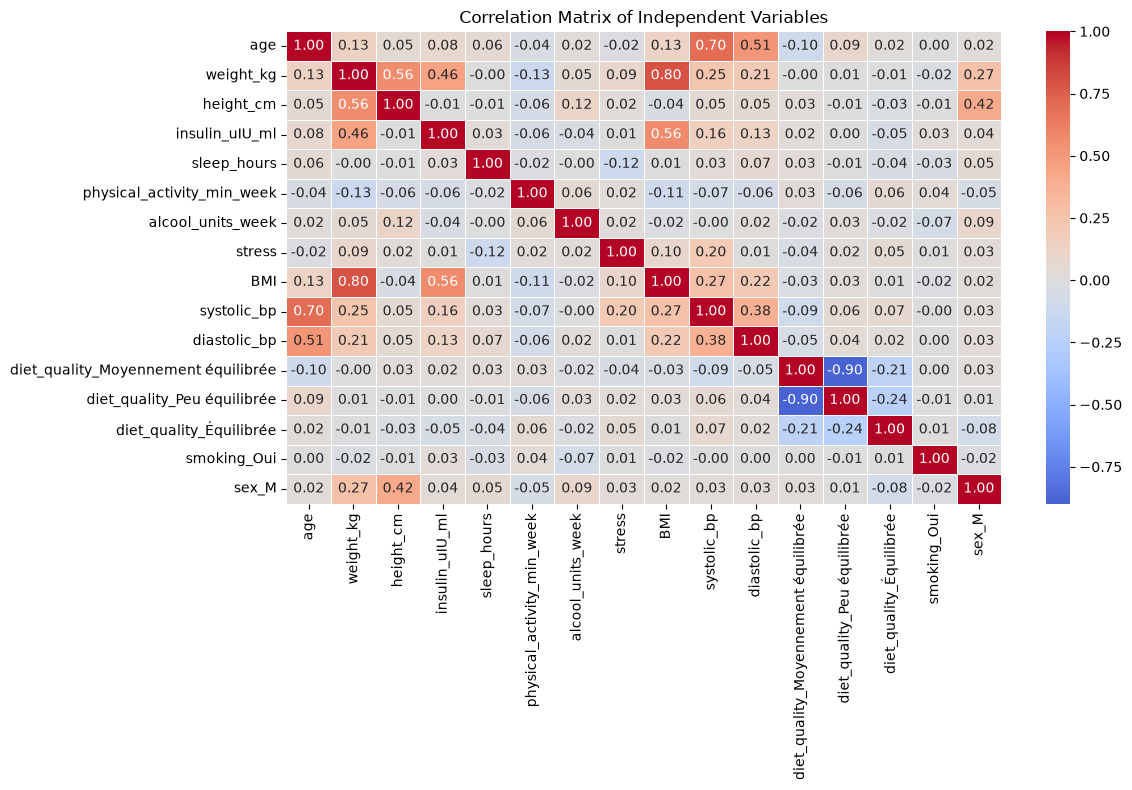

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation matrix using training features
corr_matrix = X.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Independent Variables")
plt.tight_layout()
plt.show()

Since weight and BMI are highly corelated. we can drop weight for model training

In [69]:
X = X.drop(columns=['weight_kg'])

In [70]:
X.head(3)

,age,height_cm,insulin_uIU_ml,sleep_hours,physical_activity_min_week,alcool_units_week,stress,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée,smoking_Oui,sex_M
0,37,157.1,9.1,7.6,197.0,3.6,6,19.448623,100,61,1,0,0,0,0
1,47,175.1,6.3,6.2,166.0,9.7,5,19.112844,136,65,1,0,0,0,1
2,44,172.2,12.7,7.0,118.0,0.0,5,32.037403,114,59,0,1,0,0,0


##### **Train_Test_Split data**

In [71]:
# Always split first, then fit the scaler on the training set only to avoid data leakage.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [72]:
print(f"X_train_shape : {X_train.shape}")   # check X_train shape
print(f"X_test_shape : {X_test.shape}")     # check X_test shape
print(f"y_train_shape : {y_train.shape}")   # check y_train shape
print(f"y_test_shape : {y_test.shape}")     # check y_test shape

X_train_shape : (1196, 15)
X_test_shape : (299, 15)
y_train_shape : (1196,)
y_test_shape : (299,)


In [73]:
print(type(y_test))

<class 'pandas.Series'>


#### **Scaling Features X**

In [74]:
# Scale(fit_transform) only the traning set(X_train) and use (transform) on the test set(X_test), to avoid data leakage.

from sklearn.preprocessing import MinMaxScaler

# Instantiate minmax Scaler
minmax_scaler = MinMaxScaler()

X_train_scaled = pd.DataFrame(minmax_scaler.fit_transform(X_train), 
                              columns=X_train.columns,
                              index=X_train.index)    # convert the scaled data into a dataframe and retain the X_train column names and index

X_test_scaled = pd.DataFrame(minmax_scaler.transform(X_test),
                             columns=X_test.columns,
                             index=X_test.index)      # convert the scaled data into a dataframe and retain the X_test column names and index

In [75]:
X_train_scaled.head(3)

,age,height_cm,insulin_uIU_ml,sleep_hours,physical_activity_min_week,alcool_units_week,stress,BMI,systolic_bp,diastolic_bp,diet_quality_Moyennement équilibrée,diet_quality_Peu équilibrée,diet_quality_Équilibrée,smoking_Oui,sex_M
205,0.656716,0.307273,0.181818,0.046667,0.324444,0.000000,0.5,0.427837,0.684932,0.351351,0.0,1.0,0.0,0.0,0.0
833,0.358209,0.518182,0.008658,0.045000,0.518667,0.000000,0.0,0.152452,0.315068,0.459459,0.0,1.0,0.0,1.0,0.0
309,0.805970,0.436364,0.220779,0.050000,0.278000,0.653631,0.5,0.347634,0.465753,0.729730,0.0,1.0,0.0,0.0,0.0


In [76]:
print(f"X_train_scaled_shape : {X_train_scaled.shape}")
print(f"X_test_scaled_shape : {X_test_scaled.shape}")

X_train_scaled_shape : (1196, 15)
X_test_scaled_shape : (299, 15)


## **3. Training Two Models**

#### **Train a Logistic Regression (baseline model).** 

In [77]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print(class_weights)

{np.int64(0): np.float64(0.5173010380622838), np.int64(1): np.float64(14.95)}


In [78]:
from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(max_iter=1000, random_state=42, class_weight=class_weights)

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_log = lr_model.predict(X_test_scaled)
y_prob_log = lr_model.predict_proba(X_test_scaled)[:, 1]

#### **Train a XGBoost model** 

In [79]:
scale_pos_weight = class_weights[1] / class_weights[0]

print(scale_pos_weight)

28.899999999999995


In [80]:
from xgboost import XGBClassifier

# Create initial model
xgb_model = XGBClassifier(
    objective="binary:logistic",
    random_state=42,
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight
)


**Optimize the XGBoost model by tuning Hyperparameters**

In [81]:
# Hyperparameter tuning using Grid Search
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1, 0.2],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid Search
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Fit using training data only
# Scaling is not rquired for a decision tree model
grid_search.fit(X_train, y_train)


Fitting 5 folds for each of 108 candidates, totalling 540 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.01, 0.1, ...], 'max_depth': [3, 5, ...], 'n_estimators': [100, 200, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metr

##### __*Specify the metric used to select the best hyperparameter combination and justify your choice.*__

**Evaluation Metric**: Recall (Sensitivity)  
**Recall** was selected as the primary evaluation metric for hyperparameter optimization using Grid Search with 5-fold cross-validation.  
Recall measures the proportion of actual positive cases (elevated blood glucose) correctly identified by the model.

**Justification:**
  
- **False Negatives (FN):** Elevated glucose cases incorrectly classified as normal.  
- **False Positives (FP):** Normal glucose cases incorrectly classified as elevated.  

In this health-related prediction task, false negatives are particularly concerning because potentially elevated glucose levels may go undetected.  
Therefore, maximizing recall helps minimize missed positive cases, making it an appropriate metric for selecting the best XGBoost hyperparameter combination.

In [82]:
print("Best Hyperparameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Recall:")
print(grid_search.best_score_)

Best Hyperparameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}

Best Cross-Validation Recall:
0.7


In [83]:
# Retrieve the best model
best_xgb_model = grid_search.best_estimator_

In [84]:
# Predictions
y_pred_xgb = best_xgb_model.predict(X_test)

# Predicted probabilities
y_prob_xgb = best_xgb_model.predict_proba(X_test)[:, 1]

### **5. Evaluation and Comparison of Models**

##### **Evaluate the baseline(Logistic Regression Model)**

In [85]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Precision:", precision_score(y_test, y_pred_log))
print("Recall:", recall_score(y_test, y_pred_log))
print("F1-score:", f1_score(y_test, y_pred_log))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_log))


Logistic Regression Results
---------------------------
Accuracy: 0.8695652173913043
Precision: 0.17777777777777778
Recall: 0.8
F1-score: 0.2909090909090909
ROC-AUC: 0.869204152249135


##### **Evaluate optimized XGBoost model**

In [86]:
print("XGBoost Results")
print("---------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1-score:", f1_score(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))


XGBoost Results
---------------------------
Accuracy: 0.8896321070234113
Precision: 0.15151515151515152
Recall: 0.5
F1-score: 0.23255813953488372
ROC-AUC: 0.8588235294117648


**Display the confusion matrix:**

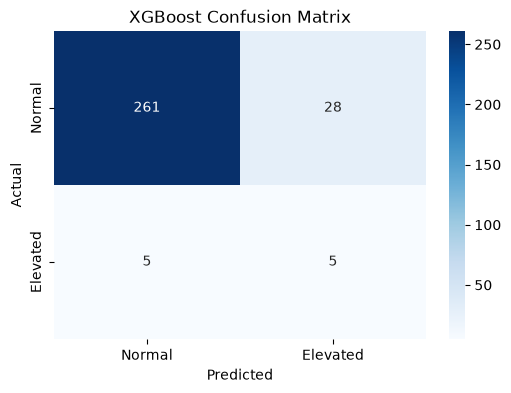

In [87]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Elevated"],
    yticklabels=["Normal", "Elevated"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix")
plt.show()

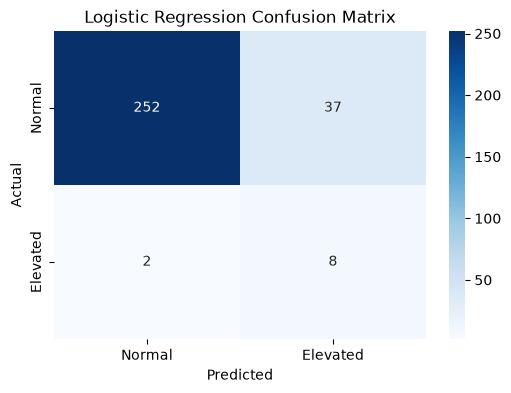

In [88]:
cm1 = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm1,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Elevated"],
    yticklabels=["Normal", "Elevated"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

**Comparison of models**

In [89]:
# comparison table to determine which model performs better.

results = pd.DataFrame({
    "Model": ["Logistic Regression", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_xgb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_xgb)
    ],
    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_xgb)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_xgb)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_log),
        roc_auc_score(y_test, y_prob_xgb)
    ]
})

results = results.set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.87,0.178,0.8,0.291,0.869
XGBoost,0.89,0.152,0.5,0.233,0.859


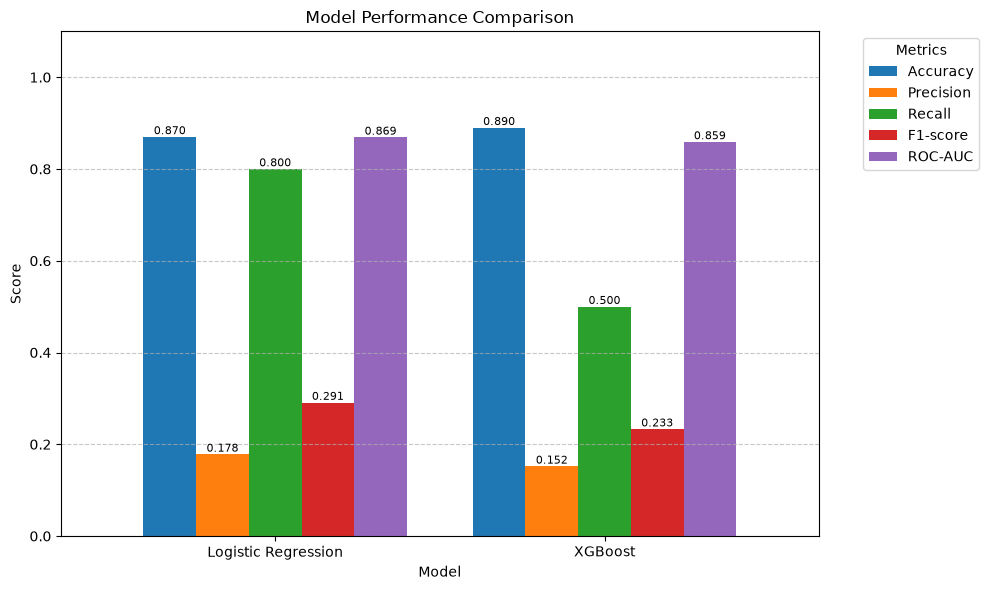

In [90]:
# Plot
ax = results.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(title="Metrics", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Add value labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8)

plt.tight_layout()
plt.show()


#### **Observed Differences**  

- ***Accuracy***: XGBoost achieves slightly higher accuracy (89%) than Logistic Regression (87%), indicating a small improvement in overall classification performance.  

- ***Precision***:  Logistic Regression has higher precision (17.8%) than XGBoost (15.2%), meaning a larger proportion of patients predicted as having elevated blood glucose are actually positive.  

- ***Recall***:  Logistic Regression substantially outperforms XGBoost in recall (80% vs. 50%), meaning it identifies a much larger proportion of individuals with elevated blood glucose and **produces fewer false negatives.**    
This is particularly important in a healthcare screening context, where missing at-risk patients can have serious consequences.

- ***F1-score***:  Logistic Regression achieves a higher F1-score (0.291) than XGBoost (0.233), indicating a better balance between precision and recall.

- ***ROC-AUC***:  Logistic Regression also achieves a slightly higher ROC-AUC (0.869) compared with XGBoost (0.859), suggesting marginally better overall discriminative ability.

#### **Model Selection**  

I would choose **Logistic Regression** for predicting elevated blood glucose levels.

**Justification**

**Predictive Performance:** Although XGBoost achieved slightly higher accuracy (0.89 vs. 0.87), Logistic Regression achieved better recall (0.80 vs. 0.50), F1-score (0.291 vs. 0.233),  
and ROC-AUC (0.869 vs. 0.859). This indicates that Logistic Regression provides more balanced overall performance.

**Risk of False Negatives:** In a health screening context, missing individuals with elevated blood glucose is more serious than generating additional false positives.  
Logistic Regression has a much higher recall (80% vs. 50%), meaning it identifies more true cases and produces fewer false negatives.

**Ease of Interpretation:** Logistic Regression is easier to interpret because the coefficients and odds ratios directly show how each variable affects the probability of elevated blood glucose.  
This transparency is valuable for communicating results and understanding risk factors.

A more complex model is not necessarily better. **For this dataset, the additional complexity of XGBoost does not provide a meaningful advantage.**

### **6. Model Interpretation**

**A. Logistic Regression**

In [91]:
# coefficients of the logistic regression model as s Dataframe
coefficients = pd.DataFrame({
    "Feature": lr_model.feature_names_in_,
    "Coefficient": lr_model.coef_[0]
})

# Calculate odds ratios, since the coefficients are in log odds space.
coefficients["Odds_Ratio"] = np.exp(
    coefficients["Coefficient"]
)

# Sort by Odds Ratio
coefficients = coefficients.sort_values(by='Odds_Ratio', ascending=False)

# view the coefficients DataFrame
coefficients[[
    "Feature",
    "Coefficient",
    "Odds_Ratio"
]].reset_index(drop=True).round(3)



,Feature,Coefficient,Odds_Ratio
0,insulin_uIU_ml,6.750,854.368
1,age,5.362,213.087
2,stress,2.984,19.758
3,diet_quality_Peu équilibrée,1.018,2.768
4,systolic_bp,0.999,2.716
5,sleep_hours,0.974,2.649
6,sex_M,0.572,1.771
7,height_cm,0.506,1.659
8,diet_quality_Moyennement équilibrée,0.506,1.658
9,diastolic_bp,0.245,1.278


**Identify variables associated with an increased probability of elevated blood glucose.**  

In order of strongly associated with increased probability of elevated blood glucose.    
- *insulin_ulU_ml, age, stress, diet_quality_Peu équilibrée, systolic_bp, sleep_hours, sex_M*  

**Identify variables associated with a decreased probability of elevated blood glucose.**  
- *physical_activity_min_week, BMI, alcohol_units_week, diet_quality_Équilibrée, smoking_Oui*

**Determine which variables appear to have the strongest association with the target variable.**  
- **strongest Positive Association**:  *insulin_ulU_ml, age, stress, diet_quality_Peu équilibrée, systolic_bp.  
 (with insulin_ulU_ml and age showing by far the largest positive coefficients and odds ratios).*  
  
- **strongest Negative Association**:  *physical_activity_min_week, BMI, alcohol_units_week, diet_quality_Équilibrée.  
 (with physical_activity_min_week showing the strongest protective association, followed by BMI and alcohol_units_week).*  

**B. XGBoost and SHAP**

In [92]:
import shap

**A global SHAP summary plot (beeswarm plot) showing the most influential variables.**

In [93]:
# Create SHAP explainer
explainer = shap.TreeExplainer(best_xgb_model)

# Calculate SHAP values for test data
shap_values = explainer(X_test)

print(shap_values.shape)
print(best_xgb_model.classes_)

(299, 15)
[0 1]


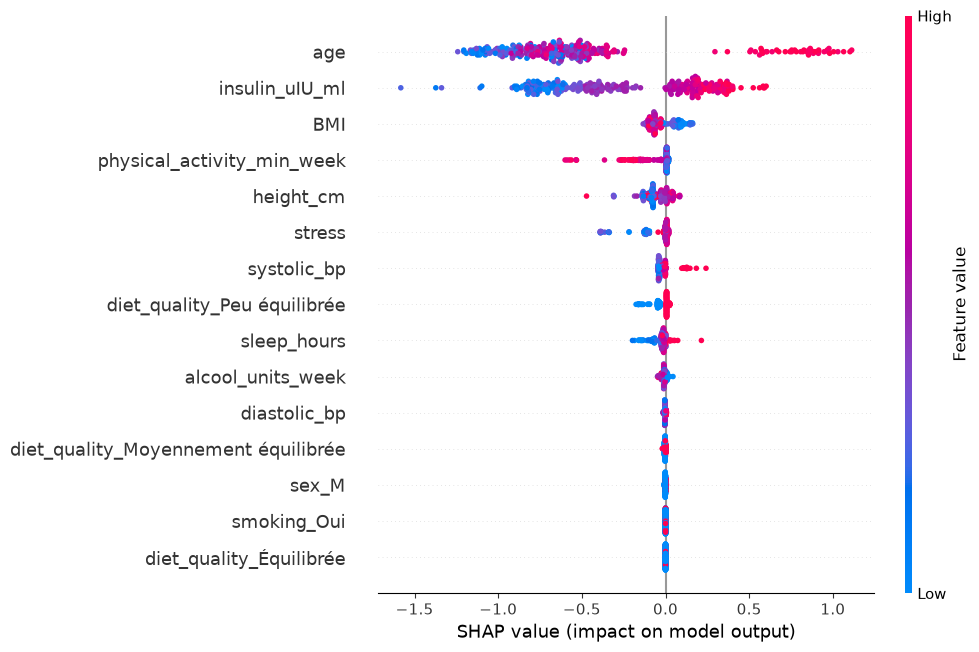

In [94]:
# SHAP summary plot
shap.plots.beeswarm(shap_values, max_display=15)

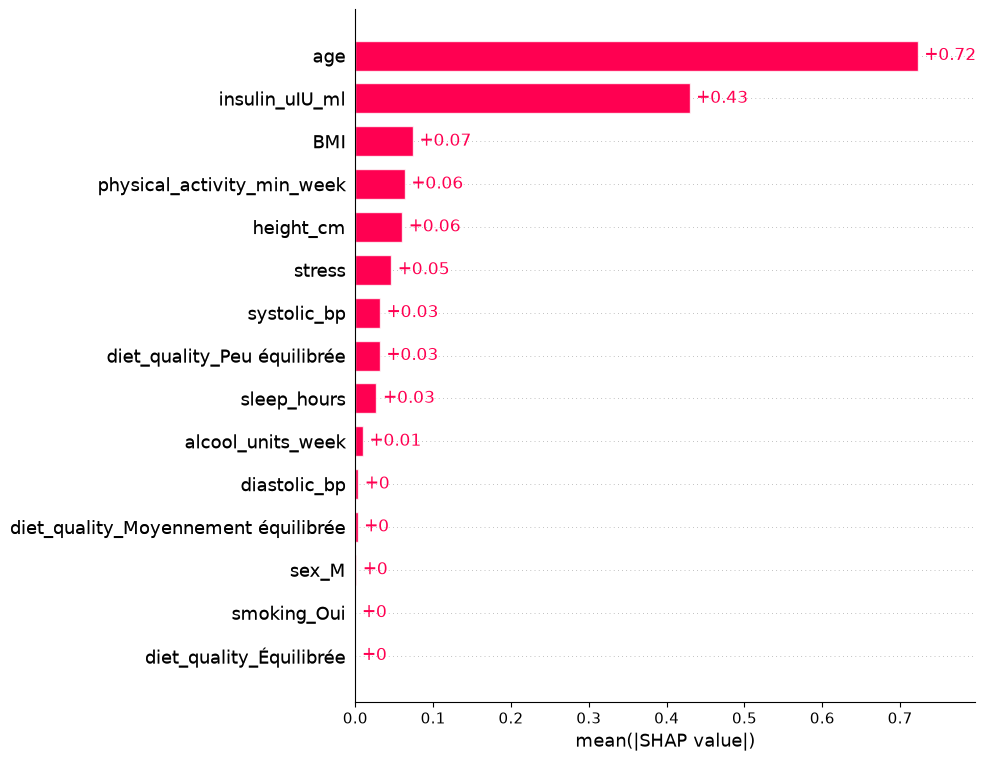

In [95]:
# feature importance – SHAP bar plot
shap.plots.bar(shap_values, max_display=15)

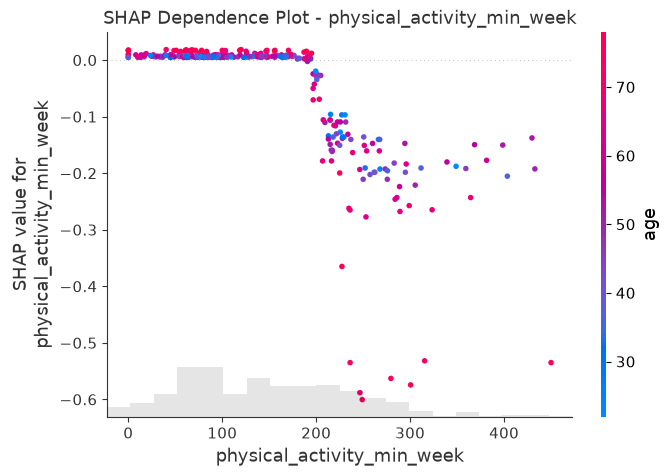

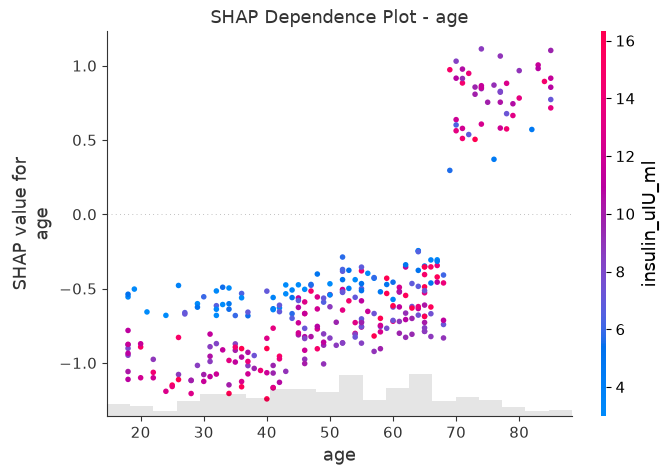

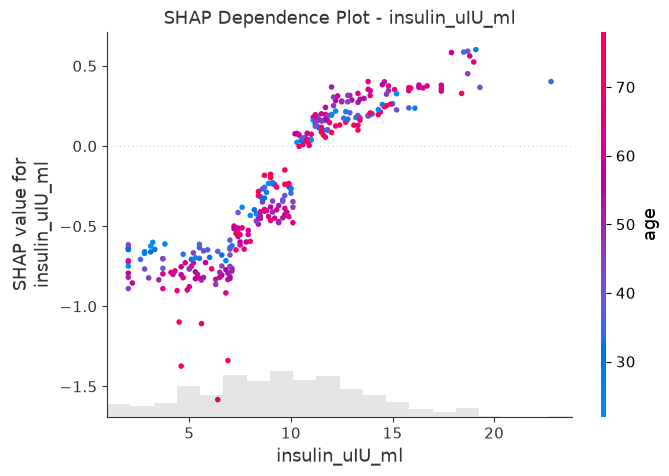

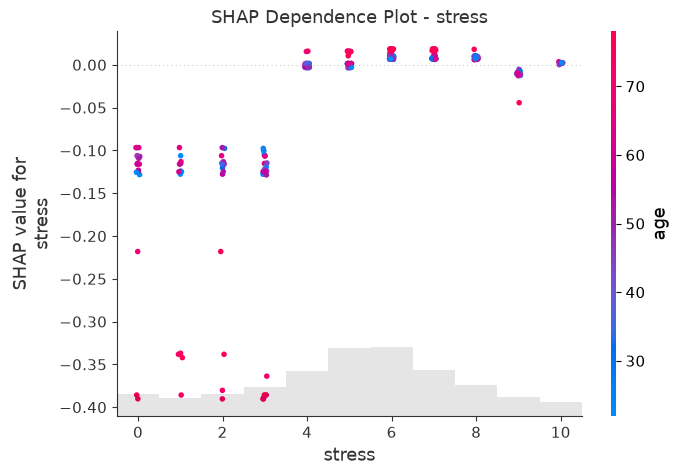

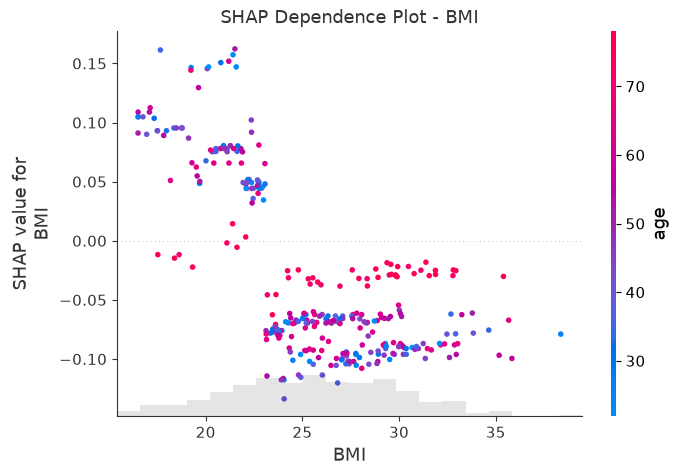

In [97]:
# Scatter plots showing the relationship between feature values and their contribution to predictions. 

features = ['physical_activity_min_week', 'age', 'insulin_uIU_ml', 'stress', 'BMI']

for feature in features:
    shap.plots.scatter(
        shap_values[:, feature],
        color=shap_values,
        title=f"SHAP Dependence Plot - {feature}"
    )

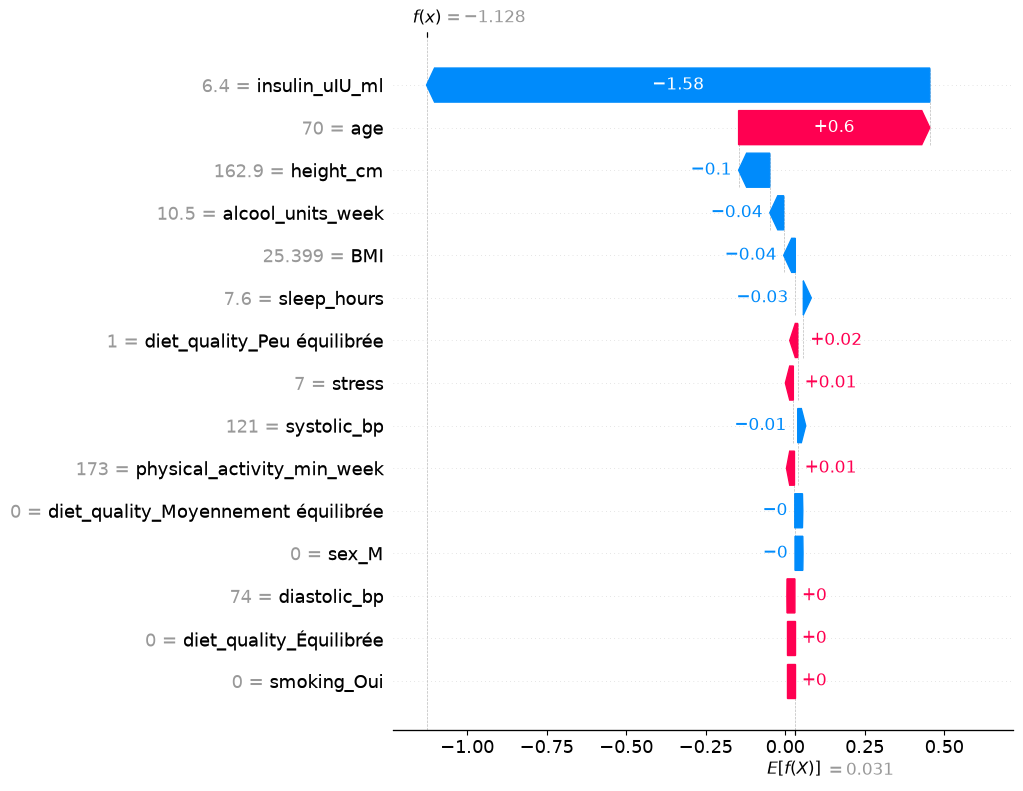

In [98]:
# A local explanation of an individual prediction / Explain the first test observation
shap.plots.waterfall(shap_values[0], max_display=15)

#### **Compare the insights obtained from SHAP with those from the logistic regression model.**

Both the SHAP analysis (XGBoost) and the Logistic Regression model identify several of the same key predictors of elevated blood glucose,  
but they provide complementary perspectives. 

**Consistent findings**: Both methods identify age and insulin_ulU_ml as the most influential predictors.  
- Logistic regression assigns the largest positive coefficients to these variables, while SHAP ranks them as the top two features based on mean absolute SHAP values.  
- Both approaches also highlight stress, systolic_bp, and diet_quality_Peu équilibrée as variables that contribute positively to elevated blood glucose.

**Differences in feature importance**:  
- SHAP identifies BMI, physical_activity_min_week, and height_cm among the most important predictors,  
- whereas logistic regression suggests that physical_activity_min_week and BMI have strong negative associations with elevated blood glucose.  
- This difference arises because SHAP measures a feature's overall contribution to model predictions, while logistic regression quantifies the direction and magnitude of a linear relationship.  

**Direction of effects**:  
Logistic regression clearly indicates whether a variable increases or decreases the probability of elevated blood glucose through the sign of its coefficient.  

**Non-linear patterns:**  
SHAP captures complex relationships and interactions learned by XGBoost that logistic regression cannot model directly.

### **7. Discussion of Results**

Most strongly associated variables: Age and insulin_ulU_ml were the strongest predictors of glycemic status in both models.  
Stress, systolic blood pressure, physical activity, and diet quality also showed important associations.  

- **Relationships observed**: Older age, higher insulin levels, greater stress, higher blood pressure, and a poorly balanced diet were associated with higher blood glucose levels.  
In contrast, greater physical activity and a balanced diet were associated with lower blood glucose levels.  

- **Do both models highlight the same factors?**  Yes. Both logistic regression and XGBoost/SHAP identified age and insulin_ulU_ml as the most important predictors  
and highlighted the importance of physical activity, BMI, stress, blood pressure, and diet quality.  

- **Does XGBoost improve predictive performance?**  Only marginally.  
XGBoost achieved slightly higher accuracy (0.89 vs. 0.87), but logistic regression achieved better recall (0.80 vs. 0.50), F1-score (0.291 vs. 0.233),  
and ROC-AUC (0.869 vs. 0.859). Overall, logistic regression provided more balanced performance and was better at identifying cases of elevated blood glucose.

**Main limitations:**

**Sample size:**  A limited sample may reduce the reliability and generalizability of the results.
**Data quality:**  Measurement errors, missing values, or self-reported lifestyle variables may affect model accuracy.
**Overfitting:**  XGBoost is more prone to overfitting than logistic regression, especially with small datasets.
**Causal interpretation:**  The analysis identifies associations, not causation; therefore, the results cannot prove that any factor directly causes changes in blood glucose levels